In [1]:
# CHƯƠNG 5 - ƯỚC LƯỢNG KHOẢNG TIN CẬY CHO KỲ VỌNG
# Dữ liệu đọc từ 3 file Excel trong thư mục Data.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Đọc các tham số đã công bố trong ví dụ 5.3 và 5.4 (không tự tạo mẫu giả).
def doc_tham_so(ten_file):
    df = pd.read_excel('Data/' + ten_file, sheet_name='Thong_so', skiprows=3, nrows=4)
    return dict(zip(df['Thong_so'], df['Gia_tri']))


In [2]:
# BẢNG SỐ LIỆU FIT VỪA KHUNG CODE / NOTEBOOK – KHÔNG CẦN CUỘN TRONG BẢNG
# Chỉ thay đổi cách trình bày, không thay dữ liệu, công thức hay các biểu đồ.
from IPython.display import HTML, display
from html import escape
import pandas as pd


def hien_thi_bang(du_lieu, tieu_de, ghi_chu="", dinh_dang=None, chieu_cao=None):
    """Bảng tự co vừa khung notebook, không có thanh cuộn dọc/ngang riêng.

    chieu_cao giữ lại để tương thích các lệnh gọi cũ, nhưng không còn giới hạn
    chiều cao bảng: toàn bộ hàng được hiển thị ngay dưới cell code.
    """
    bang = du_lieu.copy().reset_index(drop=True)
    dinh_dang = dinh_dang or {}
    so_cot = len(bang.columns)
    if so_cot == 0:
        display(HTML("<p>Không có cột dữ liệu để hiển thị.</p>"))
        return

    def dinh_dang_o(gia_tri, ten_cot):
        if pd.isna(gia_tri):
            return "—"
        mau = dinh_dang.get(ten_cot)
        if mau:
            try:
                return str(mau.format(gia_tri))
            except (ValueError, TypeError):
                pass
        return str(gia_tri)

    # Giữ nội dung trong phạm vi độ rộng ô Output. Không set min-width, không overflow:auto.
    css = """
      <style>
      .bang-fit-wrap {box-sizing:border-box!important;width:100%!important;max-width:100%!important;
         margin:12px 0 20px;padding:12px 12px 8px;border:1px solid #dce5ef;
         border-radius:10px;background:#fff;color:#1b354f;font-family:Arial,sans-serif;
         overflow:visible!important;}
      .bang-fit-top {display:flex;align-items:center;justify-content:space-between;
         flex-wrap:wrap;gap:7px;margin-bottom:7px;}
      .bang-fit-title {font-size:16px;font-weight:700;line-height:1.4;min-width:0;}
      .bang-fit-count {font-size:12px;font-weight:600;white-space:nowrap;
         color:#096d74;background:#e2f4f4;border-radius:20px;padding:4px 9px;}
      .bang-fit-note {font-size:12px;line-height:1.5;color:#516983;
         margin-bottom:9px;overflow-wrap:anywhere;}
      table.bang-fit-table {border-collapse:collapse!important;border-spacing:0!important;
         table-layout:fixed!important;width:100%!important;max-width:100%!important;
         min-width:0!important;margin:0!important;font-family:Arial,sans-serif;
         font-size:13px!important;border:1px solid #cfdeeb;}
      table.bang-fit-table thead th {box-sizing:border-box!important;text-align:center!important;
         padding:9px 5px!important;background:#173f69!important;color:#fff!important;
         font-weight:700!important;line-height:1.35!important;
         border:1px solid #3e668e!important;white-space:normal!important;
         overflow-wrap:break-word!important;word-break:normal!important;}
      table.bang-fit-table tbody td {box-sizing:border-box!important;text-align:center!important;
         padding:6px 4px!important;line-height:1.35!important;
         color:#203a55!important;border:1px solid #dfe8f0!important;
         font-variant-numeric:tabular-nums!important;white-space:normal!important;
         overflow-wrap:anywhere!important;}
      table.bang-fit-table tbody tr:nth-child(even) td {background:#f0f6fb!important;}
      table.bang-fit-table tbody tr:nth-child(odd) td {background:#fff!important;}
      table.bang-fit-table tbody tr:hover td {background:#dbf3ed!important;}
      @media (max-width: 650px) {
         .bang-fit-wrap {padding:8px 5px 5px!important;}
         .bang-fit-title {font-size:14px!important;}
         .bang-fit-note {font-size:11px!important;}
         table.bang-fit-table {font-size:11px!important;}
         table.bang-fit-table thead th {padding:7px 2px!important;}
         table.bang-fit-table tbody td {padding:5px 2px!important;}
      }
      </style>
    """
    widths = (["18%", "82%"] if so_cot == 2 else
              ["17%", "28%", "27%", "28%"] if so_cot == 4 else
              [f"{100 / so_cot:.4f}%"] * so_cot)
    headers = "".join(f'<th scope="col" style="width:{widths[i]}">{escape(str(col))}</th>'
                      for i, col in enumerate(bang.columns))
    rows = []
    for k, values in enumerate(bang.itertuples(index=False, name=None)):
        cells = "".join(
            f'<td>{escape(dinh_dang_o(value, col))}</td>'
            for col, value in zip(bang.columns, values)
        )
        rows.append(f'<tr>{cells}</tr>')
    note = f'<div class="bang-fit-note">{escape(ghi_chu)}</div>' if ghi_chu else ""
    output = (
        css + '<div class="bang-fit-wrap">'
        + '<div class="bang-fit-top">'
        + f'<div class="bang-fit-title">{escape(tieu_de)}</div>'
        + f'<span class="bang-fit-count">{len(bang)} quan sát</span>'
        + '</div>' + note
        + '<table class="bang-fit-table"><colgroup>'
        + "".join(f'<col style="width:{x}">' for x in widths)
        + '</colgroup><thead><tr>' + headers + '</tr></thead><tbody>'
        + "".join(rows)
        + '</tbody></table>'
        + '</div>'
    )
    display(HTML(output))


def hien_thi_bang_qq(bang_qq, tieu_de, so_le_x=2):
    """Bảng Q–Q bốn cột gọn; giải thích ký hiệu ở dòng ghi chú phía trên."""
    bang_ro = bang_qq.rename(columns={
        "j": "STT (j)",
        "x_j": "Giá trị (xⱼ)",
        "(j - 0,5)/n": "Xác suất (pⱼ)",
        "z_j = Φ⁻¹((j - 0,5)/n)": "Phân vị (zⱼ)",
    })
    hien_thi_bang(
        bang_ro,
        tieu_de=tieu_de,
        ghi_chu="xⱼ: số liệu tăng dần; pⱼ = (j − 0,5)/n; zⱼ = Φ⁻¹(pⱼ). Bảng tự vừa khung, hiển thị đủ tất cả các hàng.",
        dinh_dang={
            "STT (j)": "{:.0f}",
            "Giá trị (xⱼ)": "{:." + str(so_le_x) + "f}",
            "Xác suất (pⱼ)": "{:.3f}",
            "Phân vị (zⱼ)": "{:+.3f}",
        },
    )


In [3]:
# 1. BIẾT PHƯƠNG SAI - VÍ DỤ 5.3 (trang 105)
p = doc_tham_so('Vi_du_5_3_biet_phuong_sai.xlsx')
n, x_bar, sigma, alpha = int(p['n']), p['x_bar'], p['sigma'], p['alpha']

z = stats.norm.ppf(1 - alpha / 2)  # <-- DÒNG TRA GIÁ TRỊ Z (KHÔNG DÙNG T)
sai_so = z * sigma / np.sqrt(n)
print('VÍ DỤ 5.3 - ĐÃ BIẾT PHƯƠNG SAI')
print(f'Z = {z:.4f}')
print(f'Khoảng tin cậy 95%: [{x_bar-sai_so:.4f}; {x_bar+sai_so:.4f}] kg')


VÍ DỤ 5.3 - ĐÃ BIẾT PHƯƠNG SAI
Z = 1.9600
Khoảng tin cậy 95%: [49.7080; 50.4920] kg


In [4]:
# 2. CHƯA BIẾT PHƯƠNG SAI - VÍ DỤ 5.4 (trang 107)
p = doc_tham_so('Vi_du_5_4_chua_biet_phuong_sai.xlsx')
n, x_bar, s, alpha = int(p['n']), p['x_bar'], p['s'], p['alpha']

t = stats.t.ppf(1 - alpha / 2, df=n - 1)  # <-- DÒNG TRA GIÁ TRỊ T STUDENT
sai_so = t * s / np.sqrt(n)
print('VÍ DỤ 5.4 - CHƯA BIẾT PHƯƠNG SAI')
print(f'T (df={n-1}) = {t:.4f}')
print(f'Khoảng tin cậy 95%: [{x_bar-sai_so:.2f}; {x_bar+sai_so:.2f}] giờ')


VÍ DỤ 5.4 - CHƯA BIẾT PHƯƠNG SAI
T (df=15) = 2.1314
Khoảng tin cậy 95%: [23920.61; 24695.39] giờ


VÍ DỤ 5.6 - KHÔNG CHUẨN, n > 30
n = 53, trung bình = 0.5249, s = 0.3487
Shapiro-Wilk: p = 0.0157
Bác bỏ giả định phân phối chuẩn ở mức 5%
Khoảng tin cậy xấp xỉ 95%: [0.4310; 0.6188] (đơn vị 10^-4 %)
Sách trang 109 dùng x̄ = 0.52, s = 0.35 đã làm tròn: 0.43 < μ < 0.61
Lưu ý: n > 30 không làm dữ liệu gốc trở thành phân phối chuẩn.


STT (j),Giá trị (xⱼ),Xác suất (pⱼ),Phân vị (zⱼ)
1,0.04,0.009,-2.348
2,0.04,0.028,-1.906
3,0.04,0.047,-1.673
4,0.05,0.066,-1.506
5,0.10,0.085,-1.373
6,0.15,0.104,-1.260
7,0.16,0.123,-1.162
8,0.17,0.142,-1.074
9,0.18,0.160,-0.993
10,0.19,0.179,-0.918


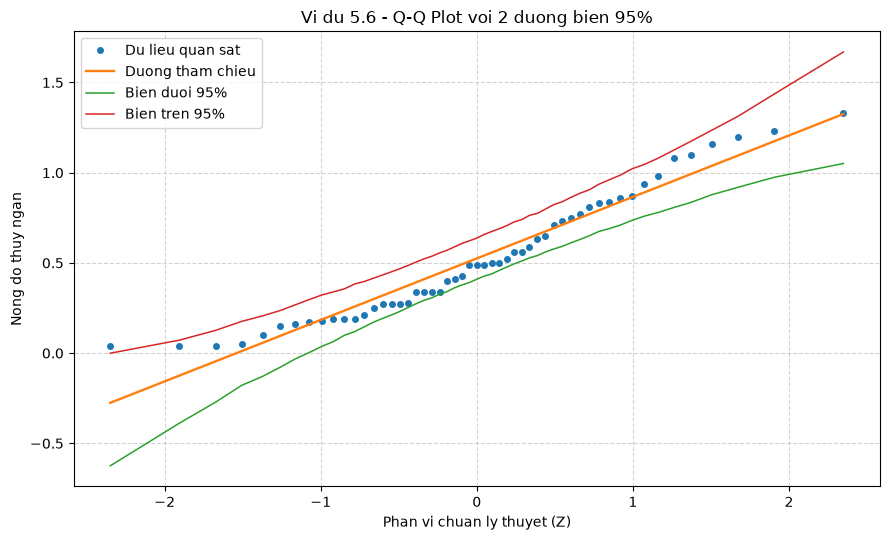

Hai duong bien la dai bao 95% theo tung phan vi cua Q-Q Plot,
KHONG phai khoang tin cay 95% cho ky vong da tinh o tren.


In [5]:
# 3. DỮ LIỆU KHÔNG CHUẨN, n > 30 - VÍ DỤ 5.6 (trang 109)
x = pd.read_excel('Data/Vi_du_5_6_n_lon_hon_30.xlsx', sheet_name='Du_lieu')['Gia_tri'].dropna().to_numpy(dtype=float)
n = len(x)
x_bar = np.mean(x)
s = np.std(x, ddof=1)                # Chưa biết phương sai tổng thể
alpha = 0.05

W, p_value = stats.shapiro(x)         # Kiểm định dữ liệu gốc có chuẩn không
z = stats.norm.ppf(1 - alpha / 2)    # <-- n > 30: TRA Z XẤP XỈ THEO GIÁO TRÌNH
sai_so = z * s / np.sqrt(n)          # Xấp xỉ theo định lý giới hạn trung tâm

print('VÍ DỤ 5.6 - KHÔNG CHUẨN, n > 30')
print(f'n = {n}, trung bình = {x_bar:.4f}, s = {s:.4f}')
print(f'Shapiro-Wilk: p = {p_value:.4f}')
print('Bác bỏ giả định phân phối chuẩn ở mức 5%' if p_value < alpha else 'Chưa bác bỏ giả định chuẩn ở mức 5%')
print(f'Khoảng tin cậy xấp xỉ 95%: [{x_bar-sai_so:.4f}; {x_bar+sai_so:.4f}] (đơn vị 10^-4 %)')
print('Sách trang 109 dùng x̄ = 0.52, s = 0.35 đã làm tròn: 0.43 < μ < 0.61')
print('Lưu ý: n > 30 không làm dữ liệu gốc trở thành phân phối chuẩn.')

# BIỂU ĐỒ XÁC SUẤT CHUẨN (Q-Q PLOT) - HÌNH 5.5
# Phân vị chuẩn lý thuyết và các quan sát được sắp xếp tăng dần
x_sorted = np.sort(x)
phan_vi = (np.arange(1, n + 1) - 0.5) / n
z_qq = stats.norm.ppf(phan_vi)

# BẢNG SỐ LIỆU TRƯỚC BIỂU ĐỒ Q-Q (giống bảng phân vị trong giáo trình)
bang_qq = pd.DataFrame({
    'j': np.arange(1, n + 1),
    'x_j': x_sorted,
    '(j - 0,5)/n': phan_vi,
    'z_j = Φ⁻¹((j - 0,5)/n)': z_qq
})
hien_thi_bang_qq(bang_qq, f'BẢNG PHÂN VỊ CHUẨN – VÍ DỤ 5.6 (n = {n})')

# Đường tham chiếu: hồi quy các quan sát theo phân vị chuẩn
he_so_goc, he_so_chan, _, _, _ = stats.linregress(z_qq, x_sorted)
duong_giua = he_so_chan + he_so_goc * z_qq

# 2 đường biên mô phỏng 95% (phân vị 2.5% và 97.5% ở mỗi vị trí)
B = 2000
rng = np.random.RandomState(42)  # Giữ kết quả biểu đồ không thay đổi giữa các lần chạy
mo_phong = rng.normal(loc=x_bar, scale=s, size=(B, n))
mo_phong_sap_xep = np.sort(mo_phong, axis=1)
bien_duoi = np.percentile(mo_phong_sap_xep, 2.5, axis=0)
bien_tren = np.percentile(mo_phong_sap_xep, 97.5, axis=0)

plt.figure(figsize=(9, 5.5))
plt.plot(z_qq, x_sorted, 'o', markersize=4, label='Du lieu quan sat')
plt.plot(z_qq, duong_giua, '-', linewidth=1.7, label='Duong tham chieu')
plt.plot(z_qq, bien_duoi, '-', linewidth=1.1, label='Bien duoi 95%')
plt.plot(z_qq, bien_tren, '-', linewidth=1.1, label='Bien tren 95%')
plt.title('Vi du 5.6 - Q-Q Plot voi 2 duong bien 95%')
plt.xlabel('Phan vi chuan ly thuyet (Z)')
plt.ylabel('Nong do thuy ngan')
plt.grid(True, linestyle='--', alpha=0.55)
plt.legend()
plt.tight_layout()
plt.show()

print('Hai duong bien la dai bao 95% theo tung phan vi cua Q-Q Plot,')
print('KHONG phai khoang tin cay 95% cho ky vong da tinh o tren.')
